In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
DATA_PATH = Path("Water Quality.csv")
TARGET_PARAMETER = "Specific conductance"
pd.set_option("display.max_columns", 50)


In [2]:
try:
    from xgboost import XGBRegressor
    from lightgbm import LGBMRegressor
except ImportError as exc:
    raise ImportError("Install packages using %pip install xgboost lightgbm, then restart the kernel.") from exc

print("Boosting packages imported successfully.")


Boosting packages imported successfully.


In [8]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nCSV files in the current directory:")
for file in os.listdir():
    if file.lower().endswith(".csv"):
        print(file)

Current working directory:
c:\Users\YASH\Desktop\BrainyBeam\daily task

CSV files in the current directory:
AquaInsight_SPC_signal_summary.csv
Task3_RandomForest_model_metrics.csv
Task3_RandomForest_predictions.csv
Water Quality.csv


In [9]:
import pandas as pd

df = pd.read_csv("Water Quality.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset loaded successfully!
Shape: (229916, 40)

Column names:
['DatasetName', 'MonitoringLocationID', 'MonitoringLocationName', 'MonitoringLocationLatitude', 'MonitoringLocationLongitude', 'MonitoringLocationHorizontalCoordinateReferenceSystem', 'MonitoringLocationHorizontalAccuracyMeasure', 'MonitoringLocationHorizontalAccuracyUnit', 'MonitoringLocationVerticalMeasure', 'MonitoringLocationVerticalUnit', 'MonitoringLocationType', 'ActivityType', 'ActivityMediaName', 'ActivityStartDate', 'ActivityStartTime', 'ActivityEndDate', 'ActivityEndTime', 'ActivityDepthHeightMeasure', 'ActivityDepthHeightUnit', 'SampleCollectionEquipmentName', 'CharacteristicName', 'MethodSpeciation', 'ResultSampleFraction', 'ResultValue', 'ResultUnit', 'ResultValueType', 'ResultDetectionCondition', 'ResultDetectionQuantitationLimitMeasure', 'ResultDetectionQuantitationLimitUnit', 'ResultDetectionQuantitationLimitType', 'ResultStatusID', 'ResultComment', 'ResultAnalyticalMethodID', 'ResultAnalyticalMethodContex

,DatasetName,MonitoringLocationID,MonitoringLocationName,MonitoringLocationLatitude,MonitoringLocationLongitude,MonitoringLocationHorizontalCoordinateReferenceSystem,MonitoringLocationHorizontalAccuracyMeasure,MonitoringLocationHorizontalAccuracyUnit,MonitoringLocationVerticalMeasure,MonitoringLocationVerticalUnit,MonitoringLocationType,ActivityType,ActivityMediaName,ActivityStartDate,ActivityStartTime,ActivityEndDate,ActivityEndTime,ActivityDepthHeightMeasure,ActivityDepthHeightUnit,SampleCollectionEquipmentName,CharacteristicName,MethodSpeciation,ResultSampleFraction,ResultValue,ResultUnit,ResultValueType,ResultDetectionCondition,ResultDetectionQuantitationLimitMeasure,ResultDetectionQuantitationLimitUnit,ResultDetectionQuantitationLimitType,ResultStatusID,ResultComment,ResultAnalyticalMethodID,ResultAnalyticalMethodContext,ResultAnalyticalMethodName,AnalysisStartDate,AnalysisStartTime,AnalysisStartTimeZone,LaboratoryName,LaboratorySampleID
0,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,River/Stream,Sample-Routine,Surface Water,2000-01-03,12:00:00,NaN,NaN,NaN,NaN,NaN,Aluminum,NaN,Extractable,254.70,ug/L,Actual,NaN,NaN,ug/L,NaN,Preliminary,NaN,110688,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN
1,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,River/Stream,Sample-Routine,Surface Water,2000-01-03,12:00:00,NaN,NaN,NaN,NaN,NaN,Apparent color,NaN,NaN,133.00,TCU,Actual,NaN,NaN,TCU,NaN,Preliminary,NaN,2011,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN
2,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,River/Stream,Sample-Routine,Surface Water,2000-01-03,12:00:00,NaN,NaN,NaN,NaN,NaN,Calcium,NaN,Dissolved,1.10,mg/L,Actual,NaN,NaN,mg/L,NaN,Preliminary,NaN,20110,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN
3,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,River/Stream,Sample-Routine,Surface Water,2000-01-03,12:00:00,NaN,NaN,NaN,NaN,NaN,Chloride,NaN,Dissolved,6.13,mg/L,Actual,NaN,NaN,mg/L,NaN,Preliminary,NaN,17209,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN
4,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,River/Stream,Sample-Routine,Surface Water,2000-01-03,12:00:00,NaN,NaN,NaN,NaN,NaN,Gran acid neutralizing capacity,NaN,NaN,-0.24,mg/L,Actual,NaN,NaN,mg/L,NaN,Preliminary,NaN,10110,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN


In [ ]:
import pandas as pd

print("Available DataFrames:")

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(f"{name}: {obj.shape}")

Available DataFrames:
df: (229916, 40)


In [13]:
# Find parameter names containing "conductance"
conductance_names = (
    df.loc[
        df["CharacteristicName"].astype(str).str.contains(
            "conductance", case=False, na=False
        ),
        "CharacteristicName"
    ]
    .value_counts()
)

print(conductance_names.head(20))

CharacteristicName
Specific conductance    8963
Name: count, dtype: int64


In [14]:
print("Available columns:")
print(df.columns.tolist())

print("\nExample parameter names:")
print(df["CharacteristicName"].dropna().unique()[:30])

Available columns:
['DatasetName', 'MonitoringLocationID', 'MonitoringLocationName', 'MonitoringLocationLatitude', 'MonitoringLocationLongitude', 'MonitoringLocationHorizontalCoordinateReferenceSystem', 'MonitoringLocationHorizontalAccuracyMeasure', 'MonitoringLocationHorizontalAccuracyUnit', 'MonitoringLocationVerticalMeasure', 'MonitoringLocationVerticalUnit', 'MonitoringLocationType', 'ActivityType', 'ActivityMediaName', 'ActivityStartDate', 'ActivityStartTime', 'ActivityEndDate', 'ActivityEndTime', 'ActivityDepthHeightMeasure', 'ActivityDepthHeightUnit', 'SampleCollectionEquipmentName', 'CharacteristicName', 'MethodSpeciation', 'ResultSampleFraction', 'ResultValue', 'ResultUnit', 'ResultValueType', 'ResultDetectionCondition', 'ResultDetectionQuantitationLimitMeasure', 'ResultDetectionQuantitationLimitUnit', 'ResultDetectionQuantitationLimitType', 'ResultStatusID', 'ResultComment', 'ResultAnalyticalMethodID', 'ResultAnalyticalMethodContext', 'ResultAnalyticalMethodName', 'AnalysisSt

In [15]:
import pandas as pd
import numpy as np

# Work on a copy of the original dataset
data = df.copy()

# Convert dates and measurements to the correct types
data["ActivityStartDate"] = pd.to_datetime(
    data["ActivityStartDate"], errors="coerce"
)
data["ResultValue"] = pd.to_numeric(
    data["ResultValue"], errors="coerce"
)

# Remove rows missing essential fields
data = data.dropna(
    subset=[
        "MonitoringLocationID",
        "ActivityStartDate",
        "CharacteristicName",
        "ResultValue"
    ]
)

# Keep valid calendar dates
data["SampleDate"] = data["ActivityStartDate"].dt.normalize()

print("Cleaned data shape:", data.shape)
print("Unique monitoring locations:", data["MonitoringLocationID"].nunique())
print("Unique parameters:", data["CharacteristicName"].nunique())
print("Date range:", data["SampleDate"].min(), "to", data["SampleDate"].max())

Cleaned data shape: (229916, 41)
Unique monitoring locations: 58
Unique parameters: 83
Date range: 2000-01-03 00:00:00 to 2023-12-06 00:00:00


In [16]:
# Aggregate duplicate measurements
pivot_data = data.pivot_table(
    index=["MonitoringLocationID", "SampleDate"],
    columns="CharacteristicName",
    values="ResultValue",
    aggfunc="median"
).reset_index()

# Clean up the column index
pivot_data.columns.name = None

print("Pivoted dataset shape:", pivot_data.shape)
print("\nAvailable parameter columns:")
print(pivot_data.columns.tolist())

display(pivot_data.head())

Pivoted dataset shape: (7283, 85)

Available parameter columns:
['MonitoringLocationID', 'SampleDate', 'Alkalinity, total', 'Aluminum', 'Ammonia', 'Antimony', 'Apparent color', 'Arsenic', 'Barium', 'Beryllium', 'Bismuth', 'Boron', 'Bromine', 'Cadmium', 'Calcium', 'Cerium', 'Cesium', 'Chloride', 'Chlorophyll a, uncorrected for pheophytin', 'Chromium', 'Cobalt', 'Conductivity', 'Copper', 'Depth of water column', 'Dissolved oxygen (DO)', 'Dissolved oxygen saturation', 'Europium', 'Fecal Coliform', 'Fluoride', 'Gadolinium', 'Gallium', 'Germanium', 'Gran acid neutralizing capacity', 'Hafnium', 'Hardness, carbonate', 'Holmium', 'Inorganic carbon', 'Inorganic nitrogen (nitrate and nitrite)', 'Iron', 'Lanthanum', 'Lead', 'Lithium', 'Lutetium', 'Magnesium', 'Manganese', 'Mercury', 'Molybdenum', 'Neodymium', 'Nickel', 'Niobium', 'Nitrate', 'Nitrite', 'Organic carbon', 'Orthophosphate', 'Potassium', 'Praseodymium', 'Rubidium', 'Samarium', 'Scandium', 'Selenium', 'Silicate', 'Silver', 'Sodium', 'S

,MonitoringLocationID,SampleDate,"Alkalinity, total",Aluminum,Ammonia,Antimony,Apparent color,Arsenic,Barium,Beryllium,Bismuth,Boron,Bromine,Cadmium,Calcium,Cerium,Cesium,Chloride,"Chlorophyll a, uncorrected for pheophytin",Chromium,Cobalt,Conductivity,Copper,Depth of water column,Dissolved oxygen (DO),...,Silicate,Silver,Sodium,Specific conductance,Strontium,Sulfate,Suspended Sediment Concentration (SSC),"Temperature, air","Temperature, water",Terbium,Thallium,Tin,Titanium,"Total Nitrogen, mixed forms","Total Phosphorus, mixed forms",True color,Tungsten,Turbidity,Uranium,Vanadium,Ytterbium,Yttrium,Zinc,Zirconium,pH
0,NB01BR0006,2000-09-22,NaN,NaN,NaN,NaN,107.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11.70,NaN,NaN,4.23,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0.88,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.19,0.032,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NB01BR0006,2000-10-11,NaN,NaN,NaN,NaN,274.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.70,NaN,NaN,6.47,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,2.26,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.20,0.038,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NB01BR0006,2000-11-23,NaN,NaN,NaN,NaN,215.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.10,NaN,NaN,8.71,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,2.45,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.15,0.011,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NB01BR0006,2001-04-26,1.8,NaN,NaN,NaN,158.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.13,NaN,NaN,2.18,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,1.87,27.5,NaN,0.79,20.1,NaN,NaN,NaN,NaN,NaN,NaN,0.08,0.024,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.9
4,NB01BR0006,2001-05-22,2.8,NaN,NaN,NaN,315.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.63,NaN,NaN,2.11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,2.40,23.6,NaN,0.52,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.13,0.015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.1


In [17]:
target_column = "Specific conductance"

if target_column not in pivot_data.columns:
    raise ValueError(
        f"Target '{target_column}' was not found. "
        "Check the parameter names in pivot_data.columns."
    )

# Keep only rows with a known target value
model_data = pivot_data.dropna(subset=[target_column]).copy()

# Sort chronologically
model_data = model_data.sort_values("SampleDate").reset_index(drop=True)

# Use other water-quality parameters as predictors
excluded_columns = [
    "MonitoringLocationID",
    "SampleDate",
    target_column
]

feature_columns = [
    col for col in model_data.columns
    if col not in excluded_columns
]

# Remove features that contain no usable measurements
feature_columns = [
    col for col in feature_columns
    if model_data[col].notna().any()
]

X = model_data[feature_columns].copy()
y = model_data[target_column].copy()

# Fill missing predictor values using each feature's median
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median()).fillna(0)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Features:", X.columns.tolist())
print("\nTarget:", target_column)

display(X.head())
display(y.head())

X shape: (7222, 82)
y shape: (7222,)
Features: ['Alkalinity, total', 'Aluminum', 'Ammonia', 'Antimony', 'Apparent color', 'Arsenic', 'Barium', 'Beryllium', 'Bismuth', 'Boron', 'Bromine', 'Cadmium', 'Calcium', 'Cerium', 'Cesium', 'Chloride', 'Chlorophyll a, uncorrected for pheophytin', 'Chromium', 'Cobalt', 'Conductivity', 'Copper', 'Depth of water column', 'Dissolved oxygen (DO)', 'Dissolved oxygen saturation', 'Europium', 'Fecal Coliform', 'Fluoride', 'Gadolinium', 'Gallium', 'Germanium', 'Gran acid neutralizing capacity', 'Hafnium', 'Hardness, carbonate', 'Holmium', 'Inorganic carbon', 'Inorganic nitrogen (nitrate and nitrite)', 'Iron', 'Lanthanum', 'Lead', 'Lithium', 'Lutetium', 'Magnesium', 'Manganese', 'Mercury', 'Molybdenum', 'Neodymium', 'Nickel', 'Niobium', 'Nitrate', 'Nitrite', 'Organic carbon', 'Orthophosphate', 'Potassium', 'Praseodymium', 'Rubidium', 'Samarium', 'Scandium', 'Selenium', 'Silicate', 'Silver', 'Sodium', 'Strontium', 'Sulfate', 'Suspended Sediment Concentration

,"Alkalinity, total",Aluminum,Ammonia,Antimony,Apparent color,Arsenic,Barium,Beryllium,Bismuth,Boron,Bromine,Cadmium,Calcium,Cerium,Cesium,Chloride,"Chlorophyll a, uncorrected for pheophytin",Chromium,Cobalt,Conductivity,Copper,Depth of water column,Dissolved oxygen (DO),Dissolved oxygen saturation,Europium,...,Selenium,Silicate,Silver,Sodium,Strontium,Sulfate,Suspended Sediment Concentration (SSC),"Temperature, air","Temperature, water",Terbium,Thallium,Tin,Titanium,"Total Nitrogen, mixed forms","Total Phosphorus, mixed forms",True color,Tungsten,Turbidity,Uranium,Vanadium,Ytterbium,Yttrium,Zinc,Zirconium,pH
0,4.0,86.3,0.015,0.03,34.0,0.4025,3.51,0.029,0.004,4.0,0.03,0.02,0.70,0.308,0.031,4.73,2.1,0.22,0.16,57.5,0.36,0.3,10.815,97.5,0.01,...,0.07,4.085,0.005,3.14,5.945,2.51,3.0,14.0,11.4275,0.0065,0.01,0.03,1.3,0.07,0.011,79.0,0.007,0.9,0.05,0.31,0.017,0.1995,2.13,0.045,5.15
1,4.0,184.5,0.015,0.03,119.0,0.4025,3.51,0.029,0.004,4.0,0.03,0.02,0.78,0.308,0.031,3.70,2.1,0.22,0.16,57.5,0.36,0.3,10.815,97.5,0.01,...,0.07,4.085,0.005,2.79,5.945,2.40,3.0,14.0,11.4275,0.0065,0.01,0.03,1.3,0.10,0.011,79.0,0.007,0.9,0.05,0.31,0.017,0.1995,2.13,0.045,4.61
2,4.0,101.4,0.015,0.03,31.0,0.4025,3.51,0.029,0.004,4.0,0.03,0.02,0.55,0.308,0.031,4.57,2.1,0.22,0.16,57.5,0.36,0.3,10.815,97.5,0.01,...,0.07,4.085,0.005,2.79,5.945,1.95,3.0,14.0,11.4275,0.0065,0.01,0.03,1.3,0.10,0.011,79.0,0.007,0.9,0.05,0.31,0.017,0.1995,2.13,0.045,5.11
3,4.0,254.7,0.015,0.03,133.0,0.4025,3.51,0.029,0.004,4.0,0.03,0.02,1.10,0.308,0.031,6.13,2.1,0.22,0.16,57.5,0.36,0.3,10.815,97.5,0.01,...,0.07,4.085,0.005,4.20,5.945,2.14,3.0,14.0,11.4275,0.0065,0.01,0.03,1.3,0.14,0.011,79.0,0.007,0.9,0.05,0.31,0.017,0.1995,2.13,0.045,4.75
4,4.0,254.0,0.015,0.03,112.0,0.4025,3.51,0.029,0.004,4.0,0.03,0.02,1.01,0.308,0.031,5.84,2.1,7.28,0.16,57.5,0.36,0.3,10.815,97.5,0.01,...,0.07,4.085,0.005,3.71,5.945,2.20,3.0,14.0,11.4275,0.0065,0.01,0.03,1.3,0.12,0.011,79.0,0.007,0.9,0.05,0.31,0.017,0.1995,2.13,0.045,4.65


0    29.3
1    31.6
2    27.0
3    39.3
4    37.8
Name: Specific conductance, dtype: float64

In [18]:
from sklearn.model_selection import train_test_split

# Preserve chronological order
split_index = int(len(model_data) * 0.80)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print(
    "\nTraining date range:",
    model_data["SampleDate"].iloc[0],
    "to",
    model_data["SampleDate"].iloc[split_index - 1]
)

print(
    "Testing date range:",
    model_data["SampleDate"].iloc[split_index],
    "to",
    model_data["SampleDate"].iloc[-1]
)

Training features: (5777, 82)
Testing features: (1445, 82)
Training target: (5777,)
Testing target: (1445,)

Training date range: 2000-01-03 00:00:00 to 2017-09-12 00:00:00
Testing date range: 2017-09-14 00:00:00 to 2023-12-06 00:00:00


In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    shuffle=False
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5777, 82)
X_test: (1445, 82)
y_train: (5777,)
y_test: (1445,)


In [24]:
import re

# Keep original feature names for reference
original_feature_names = X_train.columns.tolist()

# Replace unsupported punctuation with underscores
def clean_feature_name(name):
    name = str(name)
    name = re.sub(r"[^A-Za-z0-9_]+", "_", name)
    name = re.sub(r"_+", "_", name).strip("_")
    return name if name else "feature"

# Make names unique in case cleaning creates duplicates
clean_names = []
seen = {}

for name in original_feature_names:
    cleaned = clean_feature_name(name)
    count = seen.get(cleaned, 0)
    seen[cleaned] = count + 1

    if count > 0:
        cleaned = f"{cleaned}_{count}"

    clean_names.append(cleaned)

# Apply the same names to training and testing data
X_train = X_train.copy()
X_test = X_test.copy()

X_train.columns = clean_names
X_test.columns = clean_names

print("Feature names cleaned successfully!")
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("\nExample cleaned feature names:")
print(X_train.columns.tolist()[:20])

Feature names cleaned successfully!
Training data shape: (5777, 82)
Testing data shape: (1445, 82)

Example cleaned feature names:
['Alkalinity_total', 'Aluminum', 'Ammonia', 'Antimony', 'Apparent_color', 'Arsenic', 'Barium', 'Beryllium', 'Bismuth', 'Boron', 'Bromine', 'Cadmium', 'Calcium', 'Cerium', 'Cesium', 'Chloride', 'Chlorophyll_a_uncorrected_for_pheophytin', 'Chromium', 'Cobalt', 'Conductivity']


In [25]:
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# Time-ordered cross-validation
tscv = TimeSeriesSplit(n_splits=3)

# XGBoost
xgb_model = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_params = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.03, 0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=xgb_params,
    n_iter=10,
    scoring="neg_root_mean_squared_error",
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("Training XGBoost...")
xgb_search.fit(X_train, y_train)

print("Best XGBoost parameters:", xgb_search.best_params_)


# LightGBM
lgb_model = LGBMRegressor(
    random_state=42,
    verbosity=-1,
    n_jobs=-1
)

lgb_params = {
    "n_estimators": [100, 200, 300],
    "max_depth": [-1, 5, 10],
    "learning_rate": [0.03, 0.05, 0.1],
    "num_leaves": [15, 31, 50],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}

lgb_search = RandomizedSearchCV(
    estimator=lgb_model,
    param_distributions=lgb_params,
    n_iter=10,
    scoring="neg_root_mean_squared_error",
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("\nTraining LightGBM...")
lgb_search.fit(X_train, y_train)

print("Best LightGBM parameters:", lgb_search.best_params_)

print("\nBoth models have been trained successfully!")

Training XGBoost...
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best XGBoost parameters: {'subsample': 1.0, 'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.03, 'colsample_bytree': 0.8}

Training LightGBM...
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best LightGBM parameters: {'subsample': 0.8, 'num_leaves': 15, 'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 0.8}

Both models have been trained successfully!


In [27]:
from lightgbm import LGBMRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=3)

lgb_model = LGBMRegressor(
    random_state=42,
    verbosity=-1,
    n_jobs=-1
)

lgb_params = {
    "n_estimators": [100, 200, 300],
    "max_depth": [-1, 5, 10],
    "learning_rate": [0.03, 0.05, 0.1],
    "num_leaves": [15, 31, 50],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}

lgb_search = RandomizedSearchCV(
    estimator=lgb_model,
    param_distributions=lgb_params,
    n_iter=10,
    scoring="neg_root_mean_squared_error",
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("Training LightGBM...")

lgb_search.fit(X_train, y_train)

print("\nLightGBM training completed!")
print("Best parameters:", lgb_search.best_params_)
print("Best cross-validation RMSE:", -lgb_search.best_score_)

Training LightGBM...
Fitting 3 folds for each of 10 candidates, totalling 30 fits

LightGBM training completed!
Best parameters: {'subsample': 0.8, 'num_leaves': 15, 'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 0.8}
Best cross-validation RMSE: 57.53406447234712


In [29]:
# Create the test dataset using the same chronological split
split_index = len(X_train)

test = model_data.iloc[split_index:].copy().reset_index(drop=True)

# Confirm that the dates match the test targets
print("Test rows:", len(test))
print("Test targets:", len(y_test))
print("Date column available:", "SampleDate" in test.columns)

display(test[["SampleDate"]].head())

Test rows: 1445
Test targets: 1445
Date column available: True


,SampleDate
0,2017-09-14
1,2017-09-14
2,2017-09-26
3,2017-09-28
4,2017-09-28


In [30]:
print("Test dates:", len(test["SampleDate"]))
print("Observed values:", len(y_test))

for name, values in predictions.items():
    print(f"{name} predictions:", len(values))

Test dates: 1445
Observed values: 1445
Median baseline predictions: 1445
XGBoost predictions: 1445
LightGBM predictions: 1445


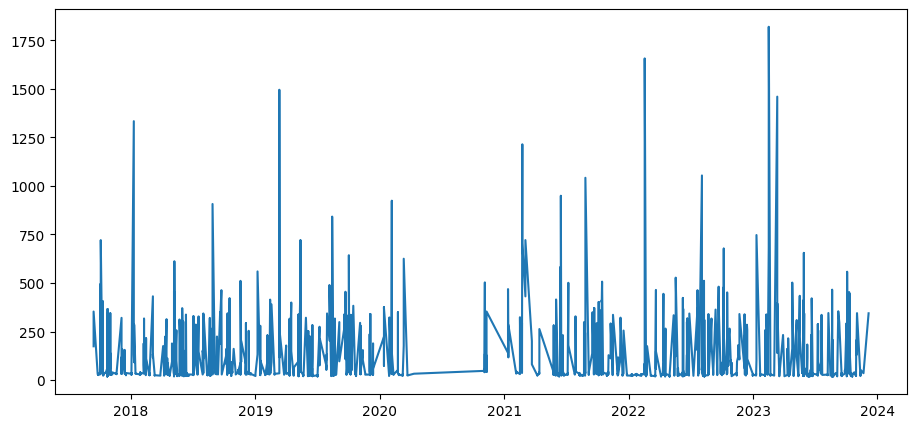

In [31]:
plt.figure(figsize=(11, 5))
plt.plot(test["SampleDate"], y_test.to_numpy(), label="Observed", linewidth=1.5)

,Model,MAE,RMSE,R2
2,LightGBM,12.2816,43.9977,0.9253
1,XGBoost,10.0437,45.8136,0.9190
0,Median baseline,73.3983,174.9632,-0.1817


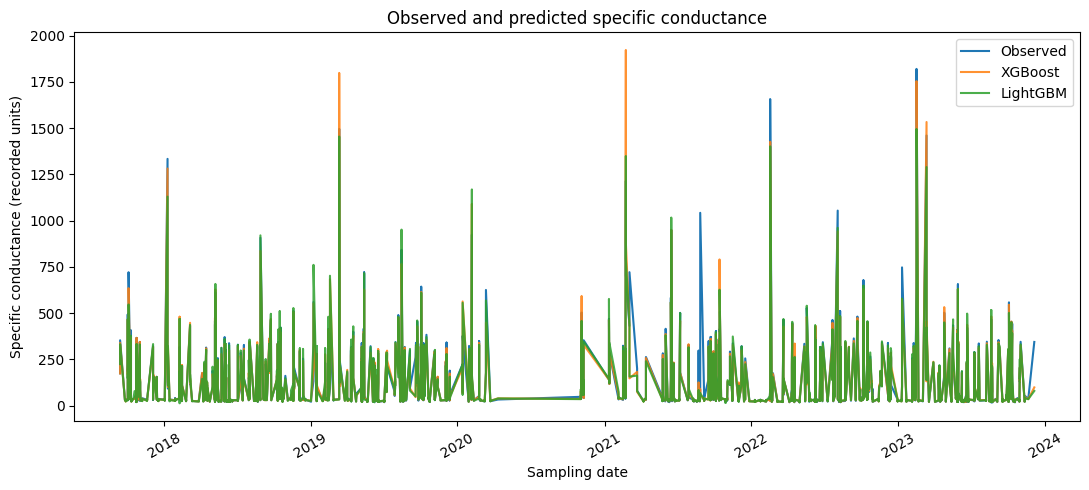

In [32]:
def metric_row(name, actual, predicted):
    return {"Model": name,
            "MAE": mean_absolute_error(actual, predicted),
            "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
            "R2": r2_score(actual, predicted) if len(actual) > 1 else np.nan}

baseline = DummyRegressor(strategy="median").fit(np.zeros((len(y_train), 1)), y_train)
predictions = {
    "Median baseline": baseline.predict(np.zeros((len(y_test), 1))),
    "XGBoost": xgb_search.best_estimator_.predict(X_test),
    "LightGBM": lgb_search.best_estimator_.predict(X_test)
}
test_metrics = pd.DataFrame([metric_row(k, y_test, v) for k, v in predictions.items()]).sort_values("RMSE")
display(test_metrics.round(4))
test_metrics.to_csv("AquaInsight_Task2_Holdout_Metrics.csv", index=False)

plt.figure(figsize=(11, 5))
plt.plot(test["SampleDate"], y_test.to_numpy(), label="Observed", linewidth=1.5)
for name in ["XGBoost", "LightGBM"]:
    plt.plot(test["SampleDate"], predictions[name], label=name, alpha=0.85)
plt.title("Observed and predicted specific conductance")
plt.xlabel("Sampling date"); plt.ylabel("Specific conductance (recorded units)")
plt.xticks(rotation=30); plt.legend(); plt.tight_layout(); plt.show()


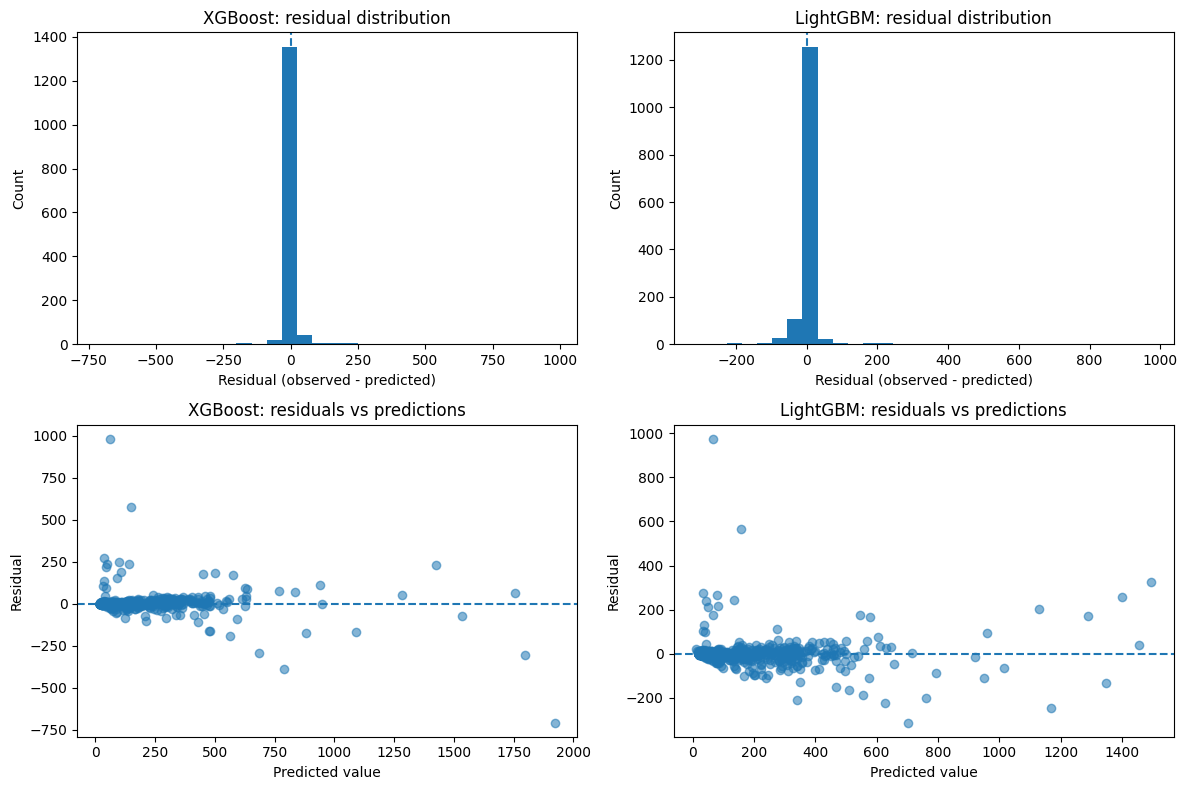

In [37]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, name in zip(axes[0], ["XGBoost", "LightGBM"]):
    resid = np.asarray(y_test) - np.asarray(predictions[name])
    ax.hist(resid, bins=30)
    ax.axvline(0, linestyle="--")
    ax.set_title(f"{name}: residual distribution")
    ax.set_xlabel("Residual (observed - predicted)")
    ax.set_ylabel("Count")
for ax, name in zip(axes[1], ["XGBoost", "LightGBM"]):
    resid = np.asarray(y_test) - np.asarray(predictions[name])
    ax.scatter(predictions[name], resid, alpha=0.55)
    ax.axhline(0, linestyle="--")
    ax.set_title(f"{name}: residuals vs predictions")
    ax.set_xlabel("Predicted value")
    ax.set_ylabel("Residual")
plt.tight_layout(); plt.show()


